# 설비 정비 시점을 강화학습으로 정하기

**강화학습은 공장에서 어떻게 일하는가** (2026.11.28 생산시스템설계 특강) PART 4 '직접 해 보기'의 실습 노트북입니다.
설비 한 대를 두고 매일 아침 '생산할까, 정비할까'를 정하는 문제를 처음부터 끝까지 풉니다.
파이썬을 설치하지 않아도 이 화면에서 바로 실행됩니다.

### 실행하는 법

1. 위 메뉴에서 **런타임 → 모두 실행**을 누릅니다(Ctrl + F9). Google 계정으로 로그인해야 합니다.
2. '이 노트는 Google에서 작성하지 않았습니다'라는 경고가 뜨면 **무시하고 계속 실행**을 누릅니다.
3. 2\~3분 기다리면 모든 표와 그림이 새로 계산됩니다. 칸 하나만 실행하려면 그 칸을 누르고 Shift + Enter를 누릅니다.

실행하기 전에도 미리 계산해 둔 결과가 보입니다. 여기서 값을 바꿔도 원본은 바뀌지 않으니 마음껏 고쳐 보세요.
고친 내용을 남기려면 **파일 → Drive에 사본 저장**을 누릅니다.

### 순서

| 단계 | 하는 일 | 발표자료 |
|---|---|---|
| [1. 언제 정비할까](#scrollTo=problem) | 문제의 숫자와 시뮬레이터 | 36쪽 |
| [2. 기존 정비 방식](#scrollTo=baselines) | 사후 · 주기 · 상태 기준 정비와 튜닝 | 37\~38쪽 |
| [3. MDP로 옮기기](#scrollTo=mdp) | 상태 · 행동 · 보상 | 39쪽 |
| [4. 강화학습 코드](#scrollTo=qlearning) | Q-learning으로 한 번 학습 | 40쪽 |
| [5. 정답(DP)](#scrollTo=dp) | 동적계획법으로 정답 계산 | 41쪽 |
| [6. 학습 곡선](#scrollTo=curve) | 다섯 번 학습하고 곡선 그리기 | 42쪽 |
| [7. 결과 비교](#scrollTo=compare) | 같은 시나리오로 공정하게 비교 | 43쪽 |
| [8. 학습된 정책](#scrollTo=policy) | 무엇을 배웠는지 열어 보기 | 44쪽 |
| [9. 더 해 보기](#scrollTo=extend) | 숫자 바꿔 보기, 도전 과제 | 45쪽 |

## 준비

아래 두 칸은 라이브러리와 한글 글꼴, 그림 그리는 도구를 준비합니다. 코드는 접혀 있고, 칸의 **코드 표시**를 누르면 펼쳐집니다.

In [1]:
#@title 준비 1 — 라이브러리와 한글 글꼴
import glob
import importlib
import importlib.util
import os
import platform
import subprocess
import sys
import time
from collections import Counter, namedtuple


T_START = time.time()


def _install(package):
    """없는 라이브러리를 조용히 설치한다."""
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", package],
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=False)
    importlib.invalidate_caches()


if importlib.util.find_spec("gymnasium") is None:          # Colab에는 이미 들어 있다
    _install("gymnasium")

import gymnasium as gym
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import font_manager


def use_korean_font():
    """그림의 한글이 네모(□)로 나오지 않게 한글 글꼴을 고른다. Colab처럼 한글 글꼴이 없는 곳에서는 나눔고딕을 받아 쓴다."""
    def registered(*names):
        have = {f.name for f in font_manager.fontManager.ttflist}
        return next((n for n in names if n in have), None)

    def add_fonts(folder):
        for path in glob.glob(os.path.join(folder, "*.ttf")):
            font_manager.fontManager.addfont(path)

    name = registered("Malgun Gothic", "AppleGothic", "NanumGothic")     # Windows, macOS, 이미 있는 나눔고딕
    if name is None:                                                     # Colab: 나눔고딕이 든 작은 패키지를 받아 글꼴만 쓴다
        if importlib.util.find_spec("koreanize_matplotlib") is None:
            _install("koreanize-matplotlib")
        spec = importlib.util.find_spec("koreanize_matplotlib")
        if spec is not None and spec.origin:
            add_fonts(os.path.join(os.path.dirname(spec.origin), "fonts"))
        name = registered("NanumGothic")
    if name is None and platform.system() == "Linux":                    # 그래도 없으면 시스템 글꼴 패키지로 한 번 더
        subprocess.run("apt-get -qq -y install fonts-nanum", shell=True, check=False,
                       stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        add_fonts("/usr/share/fonts/truetype/nanum")
        name = registered("NanumGothic", "NanumBarunGothic")
    name = name or registered("Noto Sans CJK KR", "Noto Sans KR")
    if name:
        matplotlib.rcParams["font.family"] = name
    matplotlib.rcParams["axes.unicode_minus"] = False
    return name


try:                                                       # 그림이 이 화면 안에 바로 보이게 한다 (Colab · Jupyter)
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass
FONT = use_korean_font()
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.labelsize": 10})
print(f"준비 끝: 파이썬 {platform.python_version()} · numpy {np.__version__} · gymnasium {gym.__version__}"
      f" · 한글 글꼴 {FONT or '찾지 못함(그림의 한글이 네모로 보일 수 있습니다)'}")

준비 끝: 파이썬 3.13.18 · numpy 2.5.3 · gymnasium 1.4.0 · 한글 글꼴 NanumGothic


In [2]:
#@title 준비 2 — 표와 그림 도구
TEAL, NAVY, ORANGE, RED, GRAY, INK = "#0B7A6F", "#2F4A63", "#E8A13A", "#D9573B", "#8A97A6", "#1D2733"
EVENT = {"produce": "생산", "maintain": "계획 정비", "failure": "고장 수리"}


def mean_se(v):
    """평균과 표준오차."""
    v = np.asarray(v, dtype=float)
    return float(v.mean()), float(v.std() / np.sqrt(len(v)))


def start_states(table):
    """정책 표에서 '정비를 시작하는 상태'를 (비수기, 성수기)로. 정비하지 않으면 None."""
    out = []
    for d in range(2):
        col = [int(table[c][d]) for c in range(N_COND - 1)]        # 상태 9(고장)는 자동 수리라 뺀다
        out.append(col.index(1) if 1 in col else None)
    return tuple(out)


def show_policy(table, title):
    """정책 표를 보여 준다: 칸마다 '정비' 또는 '·'(생산)."""
    frame = pd.DataFrame([["정비" if int(table[c][d]) == 1 else "·" for c in range(N_COND - 1)] for d in range(2)],
                         index=list(DEMAND_NAME), columns=[f"상태 {c}" for c in range(N_COND - 1)])
    lo, hi = start_states(table)
    name = lambda x: "없음" if x is None else x
    print(f"{title} → 정비 시작 상태: 비수기 {name(lo)}, 성수기 {name(hi)}")
    display(frame)


def draw_trace(ax, log, title, level=None):
    """설비 상태 기록 한 줄. 노란 띠 = 성수기, 초록 점 = 계획 정비, 빨간 점 = 고장, 점선 = 정비 기준."""
    n = len(log)
    t = 0
    while t < n:
        if log[t][1] == 1:
            u = t
            while u < n and log[u][1] == 1:
                u += 1
            ax.axvspan(t, u, color=ORANGE, alpha=0.18, lw=0)
            t = u
        else:
            t += 1
    ax.step(range(n), [e[0] for e in log], where="post", color=NAVY, lw=1.2)
    ax.axhline(N_COND - 1, color=RED, ls="--", lw=0.8)
    if level is not None:
        ys = [level] * n if np.isscalar(level) else list(level)
        ax.step(range(n), ys, where="post", color=NAVY, ls=":", lw=1.0)
    pm = [i for i, e in enumerate(log) if e[3] == "maintain"]
    fl = [i for i, e in enumerate(log) if e[3] == "failure"]
    ax.scatter(pm, [log[i][0] for i in pm], s=18, color=TEAL, zorder=3)
    ax.scatter(fl, [N_COND - 1] * len(fl), s=26, color=RED, zorder=3)
    ax.set_xlim(0, n)
    ax.set_ylim(-0.5, N_COND - 0.3)
    ax.set_yticks([0, 3, 6, 9])
    ax.set_title(title, loc="left", fontsize=11, fontweight="normal")


def trace_legend(fig, with_level=False):
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    items = [Line2D([], [], color=NAVY, lw=1.2, label="설비 상태"), Patch(color=ORANGE, alpha=0.3, label="성수기"),
             Line2D([], [], color=TEAL, marker="o", ls="", ms=5, label="계획 정비"),
             Line2D([], [], color=RED, marker="o", ls="", ms=5.5, label="고장")]
    if with_level:
        items.append(Line2D([], [], color=NAVY, ls=":", lw=1.0, label="정비 기준"))
    fig.legend(handles=items, loc="upper right", ncol=len(items), fontsize=9, frameon=False)


def plot_traces(items, seed=7, days=150):
    """정책 여러 개를 같은 시나리오 번호로 days일 돌려 설비 상태를 그린다. items = [(이름, 정책, 정비 기준선)]"""
    fig, axes = plt.subplots(len(items), 1, figsize=(9.2, 2.15 * len(items) + 0.7), sharex=True, squeeze=False)
    rows = []
    for ax, (name, policy, level) in zip(axes[:, 0], items):
        _, log = run_policy(policy, seed=seed, days=days, trace=True)
        if callable(level):
            level = [level(e[1]) for e in log]
        draw_trace(ax, log, name, level)
        rows.append({"방법": name, "고장": sum(e[3] == "failure" for e in log), "계획 정비": sum(e[3] == "maintain" for e in log)})
    axes[-1, 0].set_xlabel(f"날 (시나리오 번호 {seed})")
    axes[len(items) // 2, 0].set_ylabel("설비 상태 (9 = 고장)")
    trace_legend(fig, with_level=any(level is not None for _, _, level in items))
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()
    return pd.DataFrame(rows).set_index("방법")


def plot_tuning(per, thr, reac, best_n, best_k):
    """주기 n과 기준 상태 k에 따른 하루 평균 이익."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.2, 3.7), sharey=True)
    for ax, res, best, label, title in [(a1, per, best_n, "정비 주기 n (일)", "주기 정비: 며칠마다 정비할까"),
                                        (a2, thr, best_k, "정비 기준 상태 k", "상태 기준 정비: 상태 몇부터 정비할까")]:
        xs = list(res)
        m = [mean_se(res[x].profit)[0] for x in xs]
        se = [mean_se(res[x].profit)[1] for x in xs]
        ax.errorbar(xs, m, yerr=se, color=GRAY, marker="o", ms=3.5, lw=1)
        ax.scatter([best], [mean_se(res[best].profit)[0]], color=TEAL, s=70, zorder=3)
        ax.axhline(reac.profit.mean(), color=RED, ls="--", lw=0.8)
        ax.set_title(title, loc="left")
        ax.set_xlabel(label)
        ax.grid(alpha=0.3)
    a1.annotate(f"가장 좋은 주기 {best_n}일 ({per[best_n].profit.mean():.2f})", (best_n, per[best_n].profit.mean()),
                xytext=(12, 8), textcoords="offset points", color=TEAL)
    a2.annotate(f"가장 좋은 기준 상태 {best_k} ({thr[best_k].profit.mean():.2f})", (best_k, thr[best_k].profit.mean()),
                xytext=(-140, -72), textcoords="offset points", color=TEAL)
    a1.set_ylabel("하루 평균 이익")
    a2.text(max(thr), reac.profit.mean() - 0.3, "사후 정비", color=RED, ha="right", va="top")
    fig.tight_layout()
    plt.show()


def plot_curve(episodes, mean_curve, low, high, ref, n_runs):
    """학습 곡선: 진한 선 = 여러 번 학습한 평균, 옅은 띠 = 범위, 점선 = 기준선."""
    fig, ax = plt.subplots(figsize=(9.2, 4.3))
    ax.fill_between(episodes, low, high, color=TEAL, alpha=0.18, lw=0)
    ax.plot(episodes, mean_curve, color=TEAL, lw=2.2)
    colors = {"사후 정비": RED, "정답(DP)": ORANGE}
    for name, v in ref.items():
        ax.axhline(v, color=colors.get(name, GRAY), lw=1.2, ls="--" if name != "정답(DP)" else "-")
        ax.text(episodes[-1] * 1.012, v, f"{name} {v:.2f}", va="center", fontsize=9.5, color=colors.get(name, "#4A5868"))
    ax.text(episodes[-1] * 0.45, np.mean(mean_curve[-5:]) - 1.3, f"강화학습 {n_runs}회 평균, 옅은 띠 = {n_runs}회 범위", color=TEAL, fontsize=10)
    ax.axhline(0, color="#4A5868", lw=0.6)
    ax.set_xlim(1, episodes[-1])
    ax.set_xlabel("에피소드 (1회 = 1,000일)")
    ax.set_ylabel("하루 평균 이익")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


def plot_compare(results, note):
    """방법별 하루 평균 이익 막대그래프. results = {이름: 시나리오별 값}"""
    names = list(results)
    means = [float(np.mean(results[k])) for k in names]
    colors = [RED, GRAY, NAVY, TEAL, ORANGE][:len(names)]
    fig, ax = plt.subplots(figsize=(9.0, 3.6))
    ax.barh(names, means, color=colors, height=0.62)
    for i, m in enumerate(means):
        ax.text(m + (0.1 if m >= 0 else -0.1), i, f"{m:.2f}", va="center", ha="left" if m >= 0 else "right", fontsize=11, fontweight="bold")
    ax.axvline(0, color="#4A5868", lw=0.8)
    ax.set_xlim(min(-1.5, min(means) - 1.2), max(means) * 1.15)
    ax.set_xlabel(note)
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    plt.show()


def plot_policies(items):
    """정책 표를 나란히 그린다. 초록 칸 = 정비, 노란 테두리 = 첫 번째 표와 다른 칸. items = [(제목, 정책 표)]"""
    from matplotlib.patches import FancyBboxPatch
    fig, axes = plt.subplots(1, len(items), figsize=(4.6 * len(items), 1.9), squeeze=False)
    base = np.asarray(items[0][1])
    other = np.asarray(items[1][1]) if len(items) > 1 else base
    for ax, (title, table) in zip(axes[0], items):
        table = np.asarray(table)
        for d in range(2):
            for c in range(N_COND - 1):
                on = int(table[c][d]) == 1
                differs = int(base[c][d]) != int(other[c][d])
                ax.add_patch(FancyBboxPatch((c + 0.08, 1 - d + 0.1), 0.84, 0.8, boxstyle="round,pad=0,rounding_size=0.08",
                                            fc=TEAL if on else "#EEF1F4", ec=ORANGE if differs else "none", lw=2.4))
                if on:
                    ax.text(c + 0.5, 1 - d + 0.5, "정비", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        ax.set_xlim(0, N_COND - 1)
        ax.set_ylim(0, 2)
        ax.set_xticks([c + 0.5 for c in range(N_COND - 1)])
        ax.set_xticklabels(range(N_COND - 1))
        ax.xaxis.tick_top()
        ax.set_yticks([1.5, 0.5])
        ax.set_yticklabels(DEMAND_NAME, fontsize=10.5)
        ax.tick_params(length=0)
        for side in ax.spines.values():
            side.set_visible(False)
        ax.set_title(title, fontsize=11, pad=22)
    fig.tight_layout()
    plt.show()

## 1. 언제 정비할까

*발표자료 36쪽*

설비 한 대가 날마다 생산하면서 조금씩 나빠집니다. 상태는 0(새것)부터 9(고장)까지입니다.
매일 아침 '생산'과 '계획 정비' 가운데 하나를 고르고, 목표는 하루 평균 이익을 가장 크게 하는 것입니다.
문제의 숫자는 모두 아래 칸에 있습니다.

In [3]:
# 문제의 숫자 — '9. 더 해 보기'의 도전 과제에서 이 값을 바꿔 봅니다
N_COND = 10                     # 설비 상태 0..9, 9 = 고장
PROFIT = (2.0, 20.0)            # 하루 이익: (비수기, 성수기)
PM_COST, PM_DOWN = 10.0, 3      # 계획 정비: 고정비, 생산 중단 일수
RP_COST, RP_DOWN = 100.0, 6     # 고장 수리: 고정비, 생산 중단 일수
STAY = 0.95                     # 수요가 다음 날에도 그대로일 확률 (평균 20일씩 지속)
DEMAND_NAME = ("비수기", "성수기")


def deg_probs(c):
    """하루 생산한 뒤 상태가 0/1/2칸 나빠질 확률. 상태 5부터 열화가 빨라진다."""
    return (0.6, 0.3, 0.1) if c < 5 else (0.3, 0.4, 0.3)

### 시뮬레이터

이 숫자로 '하루'를 흉내 내는 시뮬레이터입니다. `step()` 한 번이 하루이고, 발표자료 40쪽의 위쪽 코드가 이 함수입니다.
강화학습 환경의 표준 틀인 Gymnasium의 `reset` · `step` 형식을 따릅니다.
정비나 수리로 멈추는 날들은 실제로 흘려보내지 않고, 그만큼의 이익을 그날 비용으로 한꺼번에 뺍니다.

In [4]:
class MaintenanceEnv(gym.Env):
    """관측 = (설비 상태 0~9, 수요 0=비수기/1=성수기), 행동 = 0 생산 / 1 계획 정비"""

    def __init__(self, horizon=1000):
        self.horizon = horizon
        self.observation_space = gym.spaces.MultiDiscrete([N_COND, 2])
        self.action_space = gym.spaces.Discrete(2)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)                 # seed = 시나리오 번호. 같은 번호·같은 행동이면 똑같이 재현된다
        self.cond, self.demand, self.t = 0, 0, 0
        return (self.cond, self.demand), {}

    def step(self, action):
        c, d = self.cond, self.demand
        event = "produce"
        if c == N_COND - 1:                                   # 고장 → 강제 수리
            reward = -(RP_COST + RP_DOWN * PROFIT[d]); self.cond = 0; event = "failure"
        elif action == 1:                                     # 계획 정비
            reward = -(PM_COST + PM_DOWN * PROFIT[d]); self.cond = 0; event = "maintain"
        else:                                                 # 생산 → 조금씩 나빠진다
            reward = PROFIT[d]
            p0, p1, _ = deg_probs(c)
            u = self.np_random.random()
            k = 0 if u < p0 else (1 if u < p0 + p1 else 2)
            self.cond = min(N_COND - 1, c + k)
        if self.np_random.random() > STAY:                    # 수요 변화
            self.demand = 1 - d
        self.t += 1
        return (self.cond, self.demand), reward, False, self.t >= self.horizon, {"event": event}

### 하루씩 돌려 보기

정비하지 않고 생산만 하면서 20일을 돌려 봅니다. 상태가 조금씩 올라가다 9에 닿으면 다음 날 강제로 수리합니다.
성수기에 고장 나면 보상이 −220(= −(100 + 6일 × 20))입니다.

In [5]:
env = MaintenanceEnv(horizon=20)
(c, d), _ = env.reset(seed=7)                 # seed = 시나리오 번호
rows = []
for day in range(1, 21):
    action = 0                                # 0 = 생산, 1 = 계획 정비 (지금은 생산만)
    (c2, d2), reward, terminated, truncated, info = env.step(action)
    rows.append({"날": day, "설비 상태": c, "수요": DEMAND_NAME[d], "행동": "생산",
                 "일어난 일": EVENT[info["event"]], "보상": reward})
    c, d = c2, d2
pd.DataFrame(rows).set_index("날")

,설비 상태,수요,행동,일어난 일,보상
날,,,,,
1,0,비수기,생산,생산,2.0
2,1,비수기,생산,생산,2.0
3,2,비수기,생산,생산,2.0
4,2,비수기,생산,생산,2.0
5,2,비수기,생산,생산,2.0
6,3,비수기,생산,생산,2.0
7,3,비수기,생산,생산,2.0
8,3,비수기,생산,생산,2.0
9,3,비수기,생산,생산,2.0


## 2. 기존 정비 방식

*발표자료 37쪽*

현장에서 흔히 쓰는 세 가지 방식입니다. 정책은 `(설비 상태, 수요, 마지막 정비 뒤 지난 날)`을 받아
행동(0 생산, 1 계획 정비)을 돌려주는 함수입니다. 세 방식 모두 수요는 보지 않습니다.

In [6]:
def reactive(c, d, since):            # 사후 정비: 정비하지 않고 고장 나면 고친다
    return 0


def periodic(n):                      # 주기 정비: n일 생산할 때마다 정비
    return lambda c, d, since: since >= n


def threshold(k):                     # 상태 기준 정비: 상태 k 이상이면 정비
    return lambda c, d, since: c >= k


def table_policy(table):              # 점수표(Q)나 DP에서 나온 정책 표를 정책으로: table[상태, 수요] = 행동
    return lambda c, d, since: table[c, d]


def run_policy(policy, seed, days=5000, trace=False):
    """시나리오 하나(seed)를 days일 돌려 하루 평균 이익을 돌려준다. trace=True면 날마다의 기록도 함께."""
    env = MaintenanceEnv(horizon=days)
    (c, d), _ = env.reset(seed=seed)
    total, since, log = 0.0, 0, []
    while True:
        a = policy(c, d, since)
        (c2, d2), r, _, trunc, info = env.step(a)
        if trace:
            log.append((c, d, a, info["event"], r))
        since = 0 if info["event"] in ("maintain", "failure") else since + 1
        total += r
        c, d = c2, d2
        if trunc:
            break
    return (total / days, log) if trace else total / days

### 같은 150일, 세 가지 방식

세 방식을 같은 시나리오 번호(seed 7)로 150일 돌린 설비 상태입니다.

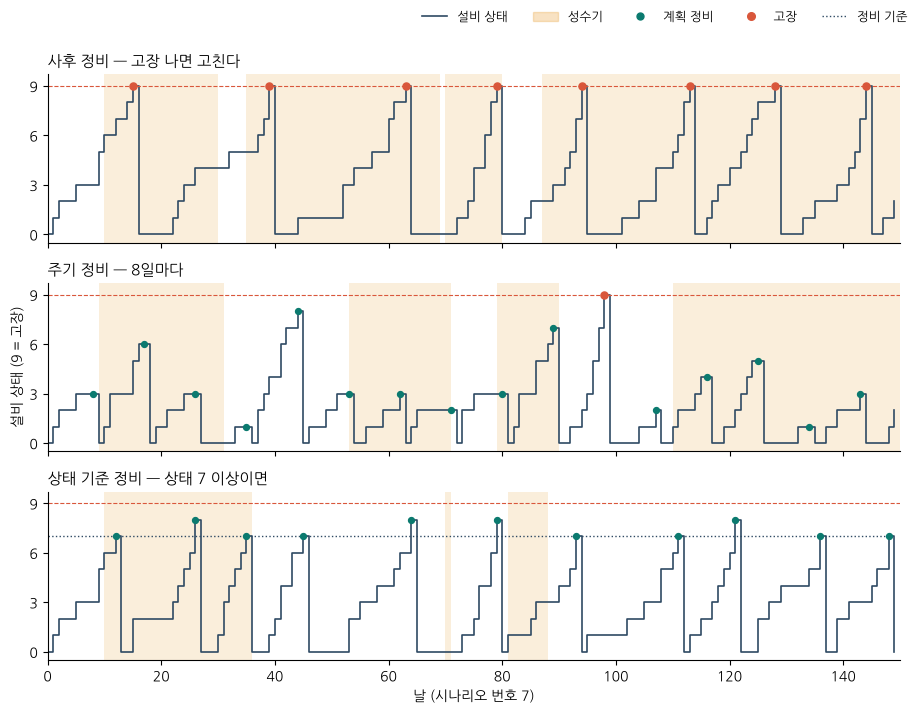

,고장,계획 정비
방법,,
사후 정비 — 고장 나면 고친다,8,0
주기 정비 — 8일마다,1,15
상태 기준 정비 — 상태 7 이상이면,0,11


In [7]:
plot_traces([("사후 정비 — 고장 나면 고친다", reactive, None),
             ("주기 정비 — 8일마다", periodic(8), None),
             ("상태 기준 정비 — 상태 7 이상이면", threshold(7), 7)])

- 사후 정비는 고장이 잦습니다. 주기 정비는 멀쩡한 설비도 정비하고, 운이 나쁘면 그 사이에 고장이 납니다.
- 상태 기준 정비는 고장이 없습니다. 하루에 많아야 2칸 나빠지므로, 상태 7 이상에서 정비하면 고장(9)에 닿지 않습니다.
- 시나리오 번호와 행동이 같으면 매번 똑같이 재현됩니다. 행동이 다르면 그 뒤 난수가 쓰이는 순서가 달라져서, 세 그림의 성수기 위치는 조금씩 다릅니다.

### 베이스라인도 튜닝한다

*발표자료 38쪽*

주기 n(2\~30일)과 기준 상태 k(1\~8)를 모두 시험해 가장 좋은 값을 고릅니다.
평가는 시나리오 200개, 각 5,000일이고 모든 방법이 같은 시나리오 번호를 씁니다.

In [8]:
N_TEST, DAYS = 200, 5000                             # 평가: 시나리오 200개 × 5,000일 (발표자료와 같은 설정)
TEST_SEEDS = list(range(2000, 2000 + N_TEST))        # 모든 방법이 같은 시나리오 번호(같은 난수)를 쓴다

In [9]:
#@title 평가 도구 — 시나리오 여러 개를 한꺼번에 돌린다 (simulate · evaluate)
Result = namedtuple("Result", "profit failures maintenances")    # 시나리오별 하루 평균 이익, 1,000일당 고장 · 계획 정비 횟수
_random_tables = {}


def _randoms(seeds, days):
    """시나리오마다 쓸 난수를 미리 뽑아 둔다. MaintenanceEnv.reset(seed)가 만드는 난수와 순서까지 같다."""
    key = (tuple(seeds), days)
    if key not in _random_tables:
        _random_tables[key] = np.array([np.random.default_rng(s).random(2 * days) for s in seeds])
    return _random_tables[key]


def simulate(policy, seeds, days=5000):
    """run_policy를 시나리오마다 돌린 것과 똑같은 결과를, 모든 시나리오를 나란히 진행해 빨리 계산한다.
    규칙은 MaintenanceEnv.step과 같다: 생산한 날은 난수 2개(열화, 수요), 정비 · 수리한 날은 1개(수요)를 쓴다."""
    U = _randoms(seeds, days)
    S = len(seeds)
    rows = np.arange(S)
    profit = np.array(PROFIT)
    p0 = np.array([deg_probs(c)[0] for c in range(N_COND)])
    p01 = np.array([deg_probs(c)[0] + deg_probs(c)[1] for c in range(N_COND)])
    c = np.zeros(S, dtype=np.int64)          # 설비 상태
    d = np.zeros(S, dtype=np.int64)          # 수요
    since = np.zeros(S, dtype=np.int64)      # 마지막 정비 뒤 지난 날
    used = np.zeros(S, dtype=np.int64)       # 지금까지 쓴 난수 개수
    total = np.zeros(S)
    n_fail = np.zeros(S, dtype=np.int64)
    n_pm = np.zeros(S, dtype=np.int64)
    for _ in range(days):
        a = np.broadcast_to(np.asarray(policy(c, d, since)), (S,))
        fail = c == N_COND - 1                                            # 고장 → 강제 수리
        pm = ~fail & (a == 1)                                             # 계획 정비
        prod = ~(fail | pm)                                               # 생산
        today = profit[d]
        reward = np.where(fail, -(RP_COST + RP_DOWN * today), np.where(pm, -(PM_COST + PM_DOWN * today), today))
        u = U[rows, used]
        worse = (u >= p0[c]).astype(np.int64) + (u >= p01[c])             # 0/1/2칸 나빠짐
        c = np.where(prod, np.minimum(N_COND - 1, c + worse), 0)
        used += prod
        d = np.where(U[rows, used] > STAY, 1 - d, d)                      # 수요 변화
        used += 1
        since = np.where(prod, since + 1, 0)
        total += reward
        n_fail += fail
        n_pm += pm
    per_1000 = S * days / 1000
    return Result(total / days, n_fail.sum() / per_1000, n_pm.sum() / per_1000)


def evaluate(policy, seeds, days=5000):
    """시나리오별 하루 평균 이익 (numpy 배열)."""
    return simulate(policy, seeds, days).profit

In [10]:
# 확인: 한꺼번에 돌린 값(evaluate)이 시뮬레이터로 하나씩 돌린 값(run_policy)과 같은가
checks = [("사후 정비", reactive), ("주기 정비 8일", periodic(8)), ("상태 기준 7 이상", threshold(7))]
for name, policy in checks:
    one_by_one = np.array([run_policy(policy, s, DAYS) for s in TEST_SEEDS[:5]])
    same = np.array_equal(one_by_one, evaluate(policy, TEST_SEEDS[:5], DAYS))
    print(f"{name}: {'같다' if same else '다르다'} (시나리오 5개)")

사후 정비: 같다 (시나리오 5개)
주기 정비 8일: 같다 (시나리오 5개)
상태 기준 7 이상: 같다 (시나리오 5개)


In [11]:
t0 = time.time()
reac = simulate(reactive, TEST_SEEDS, DAYS)
per = {n: simulate(periodic(n), TEST_SEEDS, DAYS) for n in range(2, 31)}      # 주기 n = 2~30일
thr = {k: simulate(threshold(k), TEST_SEEDS, DAYS) for k in range(1, 9)}      # 기준 상태 k = 1~8
best_n = max(per, key=lambda n: per[n].profit.mean())
best_k = max(thr, key=lambda k: thr[k].profit.mean())
print(f"가장 좋은 주기 n = {best_n}일, 가장 좋은 기준 상태 k = {best_k}  ({time.time() - t0:.0f}초)")

rows = []
for name, res in [("사후 정비", reac),
                  (f"주기 정비 ({best_n}일)", per[best_n]),
                  (f"상태 기준 ({best_k} 이상)", thr[best_k])]:
    m, se = mean_se(res.profit)
    rows.append({"방법": name, "하루 평균 이익": m, "표준오차": se,
                 "1,000일당 고장": res.failures, "1,000일당 계획 정비": res.maintenances})
pd.DataFrame(rows).set_index("방법").round(2)

가장 좋은 주기 n = 8일, 가장 좋은 기준 상태 k = 7  (6초)


,하루 평균 이익,표준오차,"1,000일당 고장","1,000일당 계획 정비"
방법,,,,
사후 정비,-0.38,0.03,64.32,0.00
주기 정비 (8일),4.11,0.03,7.10,104.38
상태 기준 (7 이상),6.99,0.03,0.00,73.96


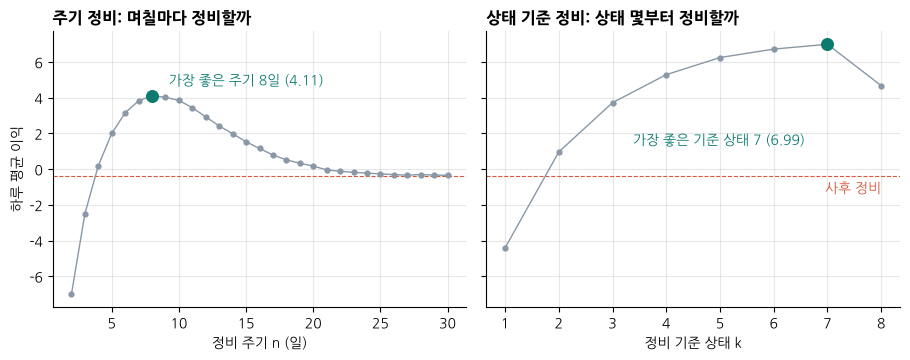

In [12]:
plot_tuning(per, thr, reac, best_n, best_k)

- **하루 평균 이익**: 5,000일 동안 번 이익을 날수로 나눈 값을 시나리오 200개에 걸쳐 평균한 것입니다.
- **표준오차**: 시나리오를 새로 뽑아 다시 재면 평균이 이 정도 흔들린다는 뜻입니다. 두 방법의 차이가 표준오차보다 충분히 커야 '다르다'고 말할 수 있습니다.
- **그래프의 산 모양**: 너무 자주 정비하면 정비 비용으로, 너무 늦추면 고장으로 손해를 봅니다. 그 사이에 가장 좋은 값이 있습니다. k = 8부터는 상태 7에서 하루 만에 9로 뛰는 일이 생겨 고장이 나기 시작합니다.
- **왜 튜닝하나**: 대충 정한 규칙과 비교하면 강화학습이 실제보다 좋아 보입니다. 비교 대상도 가장 좋은 상태로 맞춰 놓아야 공정합니다.

## 3. 마르코프 결정 과정(MDP)으로 옮기기

*발표자료 39쪽*

같은 문제를 다섯 단어로 옮깁니다. 이렇게 정리한 문제를 마르코프 결정 과정(MDP)이라고 부릅니다.

| 단어 | 이 문제에서는 | 코드 |
|---|---|---|
| 에이전트 | 매일 아침 정비 여부를 정하는 AI | 4번의 `q_learning()` |
| 환경 | 설비와 수요 | `MaintenanceEnv` |
| 상태 | (설비 상태 0\~9, 비수기 · 성수기) → 20가지 | `observation_space` |
| 행동 | 생산, 계획 정비 → 2가지 | `action_space` |
| 보상 | 그날의 이익 | `step()`이 돌려주는 값 |

In [13]:
env = MaintenanceEnv()
print("상태(관측) 공간:", env.observation_space, f"→ {N_COND} × 2 = {N_COND * 2}가지")
print("행동 공간:", env.action_space, "→ 0 생산, 1 계획 정비")
print("\n보상 (그날의 이익)")
pd.DataFrame({name: [PROFIT[d], -(PM_COST + PM_DOWN * PROFIT[d]), -(RP_COST + RP_DOWN * PROFIT[d])]
              for d, name in enumerate(DEMAND_NAME)}, index=["생산", "계획 정비", "고장 수리"])

상태(관측) 공간: MultiDiscrete([10  2]) → 10 × 2 = 20가지
행동 공간: Discrete(2) → 0 생산, 1 계획 정비

보상 (그날의 이익)


,비수기,성수기
생산,2.0,20.0
계획 정비,-16.0,-70.0
고장 수리,-112.0,-220.0


같은 정비라도 성수기에 하면 훨씬 비쌉니다(−16 대 −70). 기존 세 방식은 이 차이를 쓰지 못합니다.
그리고 에이전트는 열화 확률을 모릅니다. 시뮬레이터에서 직접 겪으며 배웁니다.

## 4. 강화학습 코드: Q-learning

*발표자료 40쪽*

점수표 `Q[설비 상태, 수요, 행동]`은 상태 20개 × 행동 2개, 40칸입니다.
1,000일짜리 연습(에피소드)을 1,000번, 모두 100만 일을 겪으며 이 표를 채웁니다.
핵심은 가운데 세 줄입니다. 탐험 또는 활용으로 행동을 고르고, 하루를 진행하고, Q값을 고칩니다.

In [14]:
def q_learning(seed, episodes=1000, horizon=1000, gamma=0.98, alpha0=0.1, alpha_min=0.005, snap_every=20):
    """에이전트는 열화 확률을 모른다. 시뮬레이터에서 겪으며 점수표 Q[상태, 수요, 행동]를 채운다.
    학습 곡선을 그리려고 snap_every 에피소드마다 그 시점의 정책(점수표에서 고른 행동)을 저장한다."""
    rng = np.random.default_rng(seed)
    Q = np.zeros((N_COND, 2, 2))
    visits = np.zeros((N_COND, 2, 2))
    env = MaintenanceEnv(horizon=horizon)
    snaps = []
    for ep in range(episodes):
        eps = max(0.05, 1.0 - ep / (0.5 * episodes))          # 탐험 비율: 처음엔 100%, 절반 지점부터 5%
        (c, d), _ = env.reset(seed=int(rng.integers(1 << 30)))
        while True:
            a = int(rng.integers(2)) if rng.random() < eps else int(np.argmax(Q[c, d]))   # 탐험 / 활용
            (c2, d2), r, _, trunc, _ = env.step(a)
            visits[c, d, a] += 1
            alpha = max(alpha_min, alpha0 / (1 + visits[c, d, a] / 500))                 # 학습률: 점점 작게
            Q[c, d, a] += alpha * (r + gamma * np.max(Q[c2, d2]) - Q[c, d, a])           # Q값 갱신
            c, d = c2, d2
            if trunc:
                break
        if ep == 0 or (ep + 1) % snap_every == 0:
            snaps.append((ep + 1, np.argmax(Q, axis=2).copy()))
    return Q, snaps

마지막 줄이 Q-learning의 전부입니다. '오늘 받은 보상 + 할인한 내일의 최고 점수'를 목표로 지금 점수를 조금씩 고칩니다.

| 설정 | 값 | 뜻 |
|---|---|---|
| `gamma` 할인율 | 0.98 | 내일의 이익을 오늘 가치로 얼마나 쳐 줄지 |
| `eps` 탐험 비율 | 100%에서 줄여 절반 지점부터 5% | 처음엔 이것저것 해 보고, 나중엔 아는 대로 |
| `alpha` 학습률 | 0.1에서 시작, 많이 겪은 칸일수록 작게(최소 0.005) | 새 경험을 얼마나 반영할지 |
| `episodes` | 1,000회 × 1,000일 | 연습량 |

### 한 번 학습해 보기

학습 한 번에 100만 일을 겪습니다. Colab에서는 20초 안팎이 걸리고, 컴퓨터에 따라 다릅니다.

In [15]:
trained = {}                                  # 학습 결과 보관: 학습 시드 → (점수표 Q, 중간 정책 기록)


def train(seed):
    """같은 학습 시드는 한 번만 학습하고, 다음부터는 보관해 둔 결과를 쓴다."""
    if seed not in trained:
        t0 = time.time()
        trained[seed] = q_learning(seed)
        print(f"학습 시드 {seed}: 에피소드 1,000회 = 100만 일의 경험, {time.time() - t0:.0f}초")
    return trained[seed]


Q, snaps = train(0)
print("\n점수표 Q — 칸마다 그 행동을 골랐을 때의 점수(앞으로 받을 보상의 할인 합)")
pd.DataFrame(Q.reshape(N_COND, 4), index=[f"상태 {c}" for c in range(N_COND)],
             columns=pd.MultiIndex.from_product([DEMAND_NAME, ["생산", "정비"]])).round(1)

학습 시드 0: 에피소드 1,000회 = 100만 일의 경험, 7초

점수표 Q — 칸마다 그 행동을 골랐을 때의 점수(앞으로 받을 보상의 할인 합)


비수기           성수기       
         생산     정비     생산     정비
상태 0  306.6  290.6  436.4  349.5
상태 1  296.6  288.3  427.1  351.2
상태 2  294.8  291.0  416.6  348.8
상태 3  292.7  289.0  400.7  349.5
상태 4  291.3  288.0  387.1  352.2
상태 5  289.0  287.1  370.8  350.7
상태 6  286.7  290.1  364.8  347.6
상태 7  253.2  289.4  306.1  351.8
상태 8  215.9  290.8  272.2  352.5
상태 9  188.0  137.4  187.7  192.3

In [16]:
show_policy(np.argmax(Q, axis=2), "강화학습이 배운 정책 (학습 시드 0)")

강화학습이 배운 정책 (학습 시드 0) → 정비 시작 상태: 비수기 6, 성수기 7


,상태 0,상태 1,상태 2,상태 3,상태 4,상태 5,상태 6,상태 7,상태 8
비수기,·,·,·,·,·,·,정비,정비,정비
성수기,·,·,·,·,·,·,·,정비,정비


점수표에서 칸마다 점수가 큰 쪽을 고른 것이 정책입니다. '정비' 점수가 '생산' 점수보다 커지는 첫 상태가 정비 시작 상태입니다.
상태 9는 고장이라 무엇을 골라도 강제로 수리하므로 정책 표에서는 뺐습니다.
점수표에서 상태 9의 두 점수가 서로 다른 것은, 덜 골라 본 칸일수록 값이 덜 다듬어졌기 때문입니다.

## 5. 정답(DP)

*발표자료 41쪽*

DP(동적계획법)는 열화 확률과 비용을 모두 안다고 가정하고, 겪어 보지 않고 계산만으로 가장 좋은 정책을 구합니다.
상태마다 생산했을 때와 정비했을 때의 기대 이익을 계산하고, 값이 더 바뀌지 않을 때까지 되풀이합니다(가치 반복).
강화학습과 같은 40칸 점수표를 채우지만, 겪어서가 아니라 계산으로 채웁니다.

In [17]:
def value_iteration(gamma=0.995):
    V = np.zeros((N_COND, 2))
    while True:
        Q = np.zeros((N_COND, 2, 2))
        for c in range(N_COND):
            for d in range(2):
                for a in range(2):
                    nxt_d = [(STAY, d), (1 - STAY, 1 - d)]
                    if c == N_COND - 1 or a == 1:
                        r = (-(RP_COST + RP_DOWN * PROFIT[d]) if c == N_COND - 1
                             else -(PM_COST + PM_DOWN * PROFIT[d]))
                        Q[c, d, a] = sum(p * (r + gamma * V[0, d2]) for p, d2 in nxt_d)
                    else:
                        Q[c, d, a] = sum(pk * p * (PROFIT[d] + gamma * V[min(N_COND - 1, c + k), d2])
                                         for k, pk in enumerate(deg_probs(c)) for p, d2 in nxt_d)
        V2 = Q.max(axis=2)
        if np.abs(V2 - V).max() < 1e-8:
            return Q
        V = V2


dp_table = np.argmax(value_iteration(), axis=2)
show_policy(dp_table, "정답(DP) 정책")

정답(DP) 정책 → 정비 시작 상태: 비수기 5, 성수기 7


,상태 0,상태 1,상태 2,상태 3,상태 4,상태 5,상태 6,상태 7,상태 8
비수기,·,·,·,·,·,정비,정비,정비,정비
성수기,·,·,·,·,·,·,·,정비,정비


4번에서 강화학습이 배운 정책과 견주어 보세요. 둘 다 성수기에는 더 버티고 비수기에는 일찍 정비합니다.
기본 설정에서는 비수기 기준만 한 칸 다릅니다(강화학습 6, 정답 5).

정답이 있는데 왜 강화학습을 쓸까요? 현실에는 확률표가 없고, 설비가 여러 대로 늘면 상태 수가 폭발해 계산 자체가 안 됩니다.
이 예제는 상태가 20개뿐이라 DP가 가능하고, 그래서 강화학습이 얼마나 잘 배웠는지 재는 채점 기준으로 씁니다.

## 6. 학습 곡선

*발표자료 42쪽*

학습 시드를 바꿔 다섯 번 따로 학습합니다. 20 에피소드마다 그 시점의 정책을 멈춰 두고 시나리오 200개로 평가합니다.

In [18]:
N_RUNS = 5                                            # 따로 학습하는 횟수 (학습 시드 0, 1, 2, ...)
runs = [train(seed) for seed in range(N_RUNS)]        # 시드 0은 4번에서 이미 학습했다

학습 시드 1: 에피소드 1,000회 = 100만 일의 경험, 6초
학습 시드 2: 에피소드 1,000회 = 100만 일의 경험, 7초
학습 시드 3: 에피소드 1,000회 = 100만 일의 경험, 6초
학습 시드 4: 에피소드 1,000회 = 100만 일의 경험, 6초


첫 에피소드 뒤의 평균 0.10  (사후 정비 -0.38)
주기 정비(4.11)를 처음 넘은 때: 20회째
정답의 95%에 닿은 때: 180회째,  99%에 닿은 때: 280회째
그 뒤로 5회 가운데 가장 낮은 값도 정답의 96% 이상


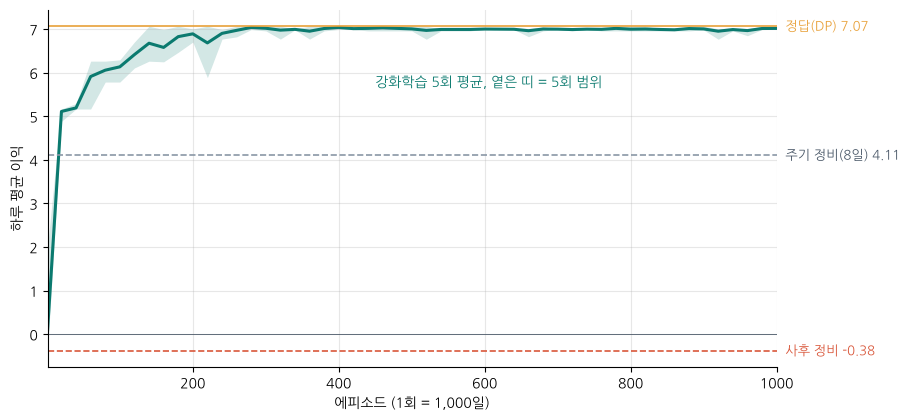

In [19]:
score_cache = {}


def score(table):
    """정책 표의 시나리오별 하루 평균 이익. 같은 정책은 한 번만 평가한다."""
    key = np.asarray(table)[:N_COND - 1].tobytes()            # 상태 9(고장)는 행동과 상관없이 수리
    if key not in score_cache:
        score_cache[key] = evaluate(table_policy(np.asarray(table)), TEST_SEEDS, DAYS)
    return score_cache[key]


episodes = [ep for ep, _ in runs[0][1]]                                             # 1, 20, 40, ..., 1000
curves = np.array([[score(t).mean() for _, t in snaps] for _, snaps in runs])       # 학습 횟수 × 평가 시점
mean_curve, low, high = curves.mean(axis=0), curves.min(axis=0), curves.max(axis=0)

dp_score = score(dp_table).mean()
name_per = f"주기 정비({best_n}일)"
ref = {"정답(DP)": dp_score, name_per: per[best_n].profit.mean(), "사후 정비": reac.profit.mean()}
first = lambda level: next((ep for ep, m in zip(episodes, mean_curve) if m >= level), None)
print(f"첫 에피소드 뒤의 평균 {mean_curve[0]:.2f}  (사후 정비 {ref['사후 정비']:.2f})")
print(f"주기 정비({ref[name_per]:.2f})를 처음 넘은 때: {first(ref[name_per])}회째")
print(f"정답의 95%에 닿은 때: {first(0.95 * dp_score)}회째,  99%에 닿은 때: {first(0.99 * dp_score)}회째")
ep99 = first(0.99 * dp_score)
if ep99 is not None:
    worst = (low[episodes.index(ep99):] / dp_score).min()
    print(f"그 뒤로 {N_RUNS}회 가운데 가장 낮은 값도 정답의 {worst * 100:.0f}% 이상")
plot_curve(episodes, mean_curve, low, high, ref, N_RUNS)

- 처음에는 거의 정비하지 않아 사후 정비 수준입니다. 기본 설정에서는 20회 만에 주기 정비를 넘고, 180회쯤 정답의 95%, 280회쯤 99%에 닿습니다.
- 중간에 오르내리는 것은 아직 탐험 중이라 점수표가 흔들리기 때문입니다.
- 280회면 28만 일입니다. 실제 공장에서 이만큼 시행착오를 하면 700년이 넘습니다. 그래서 시뮬레이터가 먼저입니다.

## 7. 결과 비교

*발표자료 43쪽*

논문의 비교 실험과 같은 틀로 모든 방법을 한 번에 비교합니다.

1. **같은 시나리오**: 모든 방법을 같은 시나리오 번호 200개로 평가합니다.
2. **튜닝한 비교 대상**: 기존 방식은 2번에서 찾은 가장 좋은 n과 k로 비교합니다.
3. **여러 번 학습**: 강화학습은 다섯 번 따로 학습해 평균과 최솟값 · 최댓값을 모두 봅니다.
4. **정답과 비교**: 작은 문제라 구할 수 있는 정답(DP)을 100%로 놓습니다.

In [20]:
finals = [score(np.argmax(Q, axis=2)) for Q, _ in runs]             # 학습마다 마지막 정책의 시나리오별 값
results = {"사후 정비": reac.profit,
           f"주기 정비 ({best_n}일)": per[best_n].profit,
           f"상태 기준 ({best_k} 이상)": thr[best_k].profit,
           f"강화학습 ({N_RUNS}회 평균)": np.mean(finals, axis=0),      # 시나리오별로 학습 5회를 평균
           "정답(DP)": score(dp_table)}

for i, ((Q_run, _), v) in enumerate(zip(runs, finals)):
    lo, hi = start_states(np.argmax(Q_run, axis=2))
    print(f"학습 {i + 1}/{N_RUNS}: 하루 평균 이익 {v.mean():.2f}, 정비 시작 상태 비수기 {lo} · 성수기 {hi}")
rl_means = [v.mean() for v in finals]
print(f"강화학습 {N_RUNS}회: 최소 {min(rl_means):.2f}, 최대 {max(rl_means):.2f}")

rows = []
for name, v in results.items():
    m, se = mean_se(v)
    rows.append({"방법": name, "하루 평균 이익": round(m, 2), "표준오차": round(se, 2),
                 "정답 대비": f"{m / dp_score * 100:.0f}%"})
pd.DataFrame(rows).set_index("방법")

학습 1/5: 하루 평균 이익 7.00, 정비 시작 상태 비수기 6 · 성수기 7
학습 2/5: 하루 평균 이익 7.07, 정비 시작 상태 비수기 5 · 성수기 7
학습 3/5: 하루 평균 이익 7.00, 정비 시작 상태 비수기 6 · 성수기 7
학습 4/5: 하루 평균 이익 7.00, 정비 시작 상태 비수기 6 · 성수기 7
학습 5/5: 하루 평균 이익 7.00, 정비 시작 상태 비수기 6 · 성수기 7
강화학습 5회: 최소 7.00, 최대 7.07


,하루 평균 이익,표준오차,정답 대비
방법,,,
사후 정비,-0.38,0.03,-5%
주기 정비 (8일),4.11,0.03,58%
상태 기준 (7 이상),6.99,0.03,99%
강화학습 (5회 평균),7.02,0.03,99%
정답(DP),7.07,0.03,100%


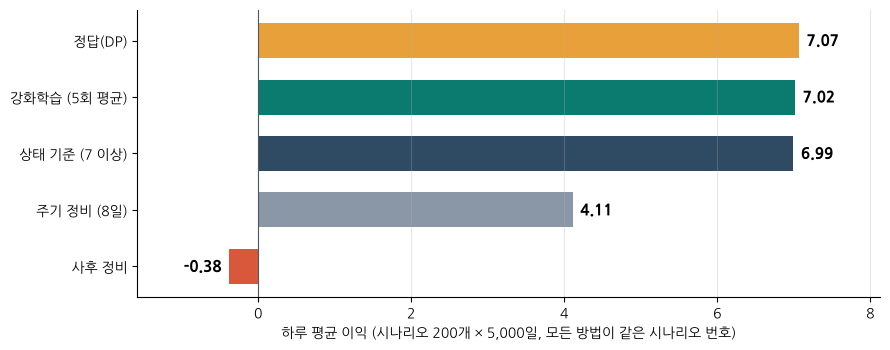

In [21]:
plot_compare(results, f"하루 평균 이익 (시나리오 {N_TEST}개 × {DAYS:,}일, 모든 방법이 같은 시나리오 번호)")

### 짝지은 비교

같은 시나리오 번호끼리 두 방법의 차이를 먼저 구하고, 그 평균과 표준오차를 봅니다.
차이가 표준오차의 2배보다 작으면 '통계적으로 구분하기 어렵다'고 판정합니다.

In [22]:
def paired(a, b):
    """같은 시나리오끼리 뺀 차이의 평균과 표준오차."""
    diff = np.asarray(a) - np.asarray(b)
    return float(diff.mean()), float(diff.std(ddof=1) / np.sqrt(len(diff)))


tables = [np.argmax(Q, axis=2) for Q, _ in runs]                     # 학습마다 마지막 정책 표
counts = Counter(t[:N_COND - 1].tobytes() for t in tables)
common_key, common_count = counts.most_common(1)[0]                  # 가장 여러 번 배운 정책
rl_table = next(t for t in tables if t[:N_COND - 1].tobytes() == common_key)

thr_values = results[f"상태 기준 ({best_k} 이상)"]
for name, values in [(f"강화학습({N_RUNS}회 중 {common_count}회가 배운 정책) − 상태 기준", score(rl_table)),
                     ("정답(DP) − 상태 기준", score(dp_table))]:
    m, se = paired(values, thr_values)
    verdict = "차이가 뚜렷하다" if abs(m) > 2 * se else "통계적으로 구분하기 어렵다"
    print(f"{name}: {m:+.3f} (표준오차 {se:.3f}) → {verdict}")

강화학습(5회 중 4회가 배운 정책) − 상태 기준: +0.012 (표준오차 0.042) → 통계적으로 구분하기 어렵다
정답(DP) − 상태 기준: +0.074 (표준오차 0.045) → 통계적으로 구분하기 어렵다


- **기본 설정에서 강화학습은 정답의 99%입니다.** 열화 확률을 모른 채 겪어서 배운 정책이 정답에 거의 닿았습니다.
- **잘 튜닝한 상태 기준 규칙도 정답만큼 좋습니다.** 강화학습과의 차이도, 정답과의 차이도 표준오차의 2배를 넘지 않습니다.
- 규칙을 제대로 튜닝하면 생각보다 강합니다. 그래서 논문에서는 강한 베이스라인이 꼭 필요합니다. 강화학습의 진짜 가치는 문제가 커져서 규칙을 튜닝하기도, 정답을 계산하기도 어려워질 때 나옵니다.

## 8. 학습된 정책

*발표자료 44쪽*

강화학습이 무엇을 배웠는지 점수표를 열어 봅니다. 칸 하나가 상태 하나이고, 초록 칸이 '정비'를 고른 상태입니다.
노란 테두리는 두 정책이 다른 칸입니다.

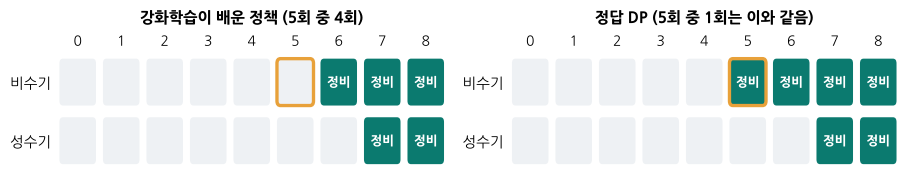

In [23]:
dp_same = sum(np.array_equal(t[:N_COND - 1], dp_table[:N_COND - 1]) for t in tables)    # 정답과 같은 횟수
plot_policies([(f"강화학습이 배운 정책 ({N_RUNS}회 중 {common_count}회)", rl_table),
               (f"정답 DP ({N_RUNS}회 중 {dp_same}회는 이와 같음)", dp_table)])

아래는 2번과 같은 150일(seed 7)을 강화학습 정책으로 돌린 모습입니다. 점선이 배운 정비 기준입니다.

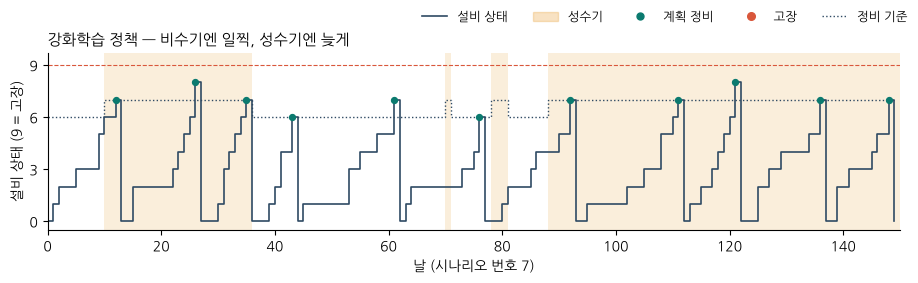

,고장,계획 정비
방법,,
"강화학습 정책 — 비수기엔 일찍, 성수기엔 늦게",0,11


In [24]:
lo, hi = start_states(rl_table)
learned_level = lambda demand: hi if demand == 1 else lo          # 배운 정비 기준: 수요에 따라 다르다
plot_traces([("강화학습 정책 — 비수기엔 일찍, 성수기엔 늦게", table_policy(rl_table), learned_level)])

수요를 보라고 알려 준 적은 없습니다. 상태에 수요를 넣어 줬을 뿐인데, 성수기 정비가 비싸다는 점을 스스로 찾아냈습니다.
논문에서는 이렇게 정책을 열어 보여 주는 해석이 꼭 필요합니다. 점수만 보여 주면 심사위원은 '왜 좋은지'를 묻습니다.

## 9. 더 해 보기

*발표자료 45쪽*

### 정확한 값으로 확인

정책이 (설비 상태, 수요)만 보고 행동을 정하면 하루하루의 변화는 마르코프 연쇄가 됩니다.
오래 돌렸을 때 각 상태에 머무는 비율(정상분포)을 구하면, 장기 하루 평균 이익이 시뮬레이션 잡음 없이 정확히 나옵니다.

In [25]:
STATES = [(c, d) for c in range(N_COND) for d in range(2)]
INDEX = {s: i for i, s in enumerate(STATES)}


def transition(table):
    """정책 표 → 전이 행렬 P와 하루 보상 r (MaintenanceEnv.step과 같은 규칙)"""
    n = len(STATES)
    P, r = np.zeros((n, n)), np.zeros(n)
    for (c, d), i in INDEX.items():
        if c == N_COND - 1:                              # 고장 → 수리
            r[i] = -(RP_COST + RP_DOWN * PROFIT[d])
            nxt = [(1.0, 0)]
        elif int(table[c][d]) == 1:                      # 계획 정비
            r[i] = -(PM_COST + PM_DOWN * PROFIT[d])
            nxt = [(1.0, 0)]
        else:                                            # 생산 → 0/1/2칸 나빠짐
            r[i] = PROFIT[d]
            nxt = [(p, min(N_COND - 1, c + k)) for k, p in enumerate(deg_probs(c))]
        for pc, c2 in nxt:
            for pd_, d2 in ((STAY, d), (1 - STAY, 1 - d)):   # 수요는 STAY 확률로 그대로
                P[i, INDEX[(c2, d2)]] += pc * pd_
    return P, r


def long_run_average(table):
    """정상분포 π (π P = π, π의 합 = 1)를 풀어 장기 하루 평균 이익을 돌려준다."""
    P, r = transition(table)
    n = len(STATES)
    A = np.vstack([P.T - np.eye(n), np.ones(n)])
    b = np.zeros(n + 1)
    b[-1] = 1.0
    pi = np.linalg.lstsq(A, b, rcond=None)[0]
    return float(pi @ r)


def rule(lo, hi):
    """비수기엔 상태 lo 이상, 성수기엔 상태 hi 이상이면 정비하는 정책 표"""
    return np.array([[int(c >= lo), int(c >= hi)] for c in range(N_COND)])


best_exact = long_run_average(dp_table)
candidates = [("사후 정비", rule(N_COND, N_COND))]
candidates += [(f"상태 기준 ({k} 이상)", rule(k, k)) for k in range(5, 9)]
candidates += [(f"강화학습 ({N_RUNS}회 중 {common_count}회가 배운 정책)", rl_table), ("정답(DP)", dp_table)]
shown = lambda x: "없음" if x is None else x
rows = []
for name, table in candidates:
    v = long_run_average(table)
    lo, hi = start_states(table)
    rows.append({"방법": name, "장기 하루 평균 이익": round(v, 3), "정답 대비": f"{v / best_exact * 100:.1f}%",
                 "정비 시작 (비수기, 성수기)": f"{shown(lo)}, {shown(hi)}"})
display(pd.DataFrame(rows).set_index("방법"))

# 비수기 · 성수기 기준을 따로 정하는 규칙(1~9 × 1~9 = 81가지)을 모두 계산하면?
v, lo, hi = max((long_run_average(rule(lo, hi)), lo, hi) for lo in range(1, N_COND) for hi in range(1, N_COND))
same = np.array_equal(rule(lo, hi)[:N_COND - 1], dp_table[:N_COND - 1])
note = "  (정답(DP)과 같은 정책)" if same else ""
print(f"수요별 기준 규칙 81가지 중 최고: 비수기 {lo}, 성수기 {hi} → {v:.3f}{note}")

,장기 하루 평균 이익,정답 대비,"정비 시작 (비수기, 성수기)"
방법,,,
사후 정비,-0.422,-6.0%,"없음, 없음"
상태 기준 (5 이상),6.263,89.0%,"5, 5"
상태 기준 (6 이상),6.695,95.1%,"6, 6"
상태 기준 (7 이상),6.995,99.4%,"7, 7"
상태 기준 (8 이상),4.668,66.3%,"8, 8"
강화학습 (5회 중 4회가 배운 정책),7.021,99.7%,"6, 7"
정답(DP),7.040,100.0%,"5, 7"


수요별 기준 규칙 81가지 중 최고: 비수기 5, 성수기 7 → 7.040  (정답(DP)과 같은 정책)


기본 설정에서 정답과 상태 기준 규칙(7 이상)의 차이는 하루 약 0.05, 정답의 0.6%입니다. 이렇게 작은 차이는 시나리오를 아주 많이 돌려야 가려집니다.
논문에서 '강화학습이 이겼다'고 쓰기 전에 차이의 크기와 표준오차를 함께 보고해야 하는 이유입니다.

### 숫자를 바꿔 보기

아래 칸에서 값을 바꾸면 정답(DP) 정책과 정확한 장기 평균 이익을 바로 다시 계산합니다. 위에서 실행한 결과는 바뀌지 않습니다.
수요를 보지 않는 규칙이 정답의 몇 %인지를 보면, 수요를 보는 정책이 언제 값어치를 하는지 알 수 있습니다.

In [26]:
#@title 숫자를 바꿔 보기 — 정답(DP) 정책은 어떻게 달라질까 { run: "auto" }
#@markdown **성수기 하루 이익** (기본 20, 비수기는 2)
PEAK_PROFIT = 20  #@param {type:"slider", min:2, max:60, step:2}
#@markdown **계획 정비 고정비** (기본 10)
PM_FIXED_COST = 10  #@param {type:"slider", min:0, max:50, step:5}
#@markdown **성수기 · 비수기가 이어지는 평균 일수** (기본 20일)
SEASON_DAYS = 20  #@param {type:"slider", min:2, max:50, step:1}


def what_if(peak_profit, pm_cost, season_days):
    """문제의 숫자를 잠깐 바꿔 정답(DP) 정책과 정확한 장기 평균 이익을 계산한 뒤, 원래 숫자로 되돌린다."""
    global PROFIT, PM_COST, STAY
    saved = (PROFIT, PM_COST, STAY)
    try:
        PROFIT, PM_COST, STAY = (PROFIT[0], float(peak_profit)), float(pm_cost), 1 - 1 / season_days
        table = np.argmax(value_iteration(), axis=2)
        best = long_run_average(table)
        k_best = max(range(1, N_COND), key=lambda k: long_run_average(rule(k, k)))
        one_rule = long_run_average(rule(k_best, k_best))
        print(f"성수기 하루 이익 {peak_profit} · 계획 정비 고정비 {pm_cost} · 수요가 이어지는 평균 일수 {season_days}")
        show_policy(table, "정답(DP) 정책")
        share = f"정답의 {one_rule / best * 100:.1f}%" if best > 0 else "정답이 0 이하라 비율은 생략"
        print(f"정확한 장기 하루 평균 이익: 정답(DP) {best:.2f} · 수요를 보지 않는 가장 좋은 규칙(상태 {k_best} 이상) {one_rule:.2f} = {share}")
        return table
    finally:
        PROFIT, PM_COST, STAY = saved


what_if_table = what_if(PEAK_PROFIT, PM_FIXED_COST, SEASON_DAYS)

성수기 하루 이익 20 · 계획 정비 고정비 10 · 수요가 이어지는 평균 일수 20
정답(DP) 정책 → 정비 시작 상태: 비수기 5, 성수기 7


,상태 0,상태 1,상태 2,상태 3,상태 4,상태 5,상태 6,상태 7,상태 8
비수기,·,·,·,·,·,정비,정비,정비,정비
성수기,·,·,·,·,·,·,·,정비,정비


정확한 장기 하루 평균 이익: 정답(DP) 7.04 · 수요를 보지 않는 가장 좋은 규칙(상태 7 이상) 6.99 = 정답의 99.4%


### 학습 설정을 바꿔 보기

괄호 안의 값을 바꿔 한 번 학습해 봅니다. 예를 들어 연습을 1,000회에서 100회로 줄이면 정답의 몇 %까지 갈까요?

In [27]:
# 바꿔 볼 것: episodes=50, episodes=200, gamma=0.9, seed=1 ...
Q_try, _ = q_learning(seed=0, episodes=100)
table_try = np.argmax(Q_try, axis=2)
show_policy(table_try, "바꾼 설정으로 배운 정책")
v = long_run_average(table_try)
print(f"정확한 장기 하루 평균 이익 {v:.3f} = 정답의 {v / best_exact * 100:.1f}%")

바꾼 설정으로 배운 정책 → 정비 시작 상태: 비수기 4, 성수기 5


,상태 0,상태 1,상태 2,상태 3,상태 4,상태 5,상태 6,상태 7,상태 8
비수기,·,·,·,·,정비,정비,정비,정비,정비
성수기,·,·,·,·,·,정비,정비,정비,정비


정확한 장기 하루 평균 이익 6.256 = 정답의 88.9%


### 도전 과제

| 과제 | 바꿀 곳 | 볼 것 |
|---|---|---|
| ① 성수기 이익이 두 배라면 | '숫자를 바꿔 보기'의 `PEAK_PROFIT`을 40으로 | 수요별 정비 시작 상태가 어떻게 바뀌나? 수요를 보지 않는 규칙과 정답의 차이가 벌어지나? |
| ② 계획 정비가 비싸다면 | `PM_FIXED_COST`를 30으로 | 정비를 얼마나 미루나? |
| ③ 수요가 자주 바뀐다면 | `SEASON_DAYS`를 5로 | 수요를 보지 않는 규칙이 정답의 몇 %까지 떨어지나? 50일로 늘리면? |
| ④ 연습을 줄이면 | '학습 설정을 바꿔 보기'의 `episodes`를 50, 100, 200으로 | 정답의 몇 %까지 가나? |
| ⑤ 먼 미래를 덜 본다면 | 같은 칸에 `gamma=0.9`를 넣기 | 수요에 따라 기준을 달리하는 정책을 여전히 배우나? |
| ⑥ 학습을 더 여러 번 | 6번의 `N_RUNS = 5`를 10으로 바꾸고 그 아래를 차례로 다시 실행 | 열 번 중 몇 번 정답과 같은 기준(비수기 5, 성수기 7)을 찾나? |
| ⑦ 탐험을 처음부터 5%로 | `q_learning()`의 `eps = max(...)` 줄을 `eps = 0.05`로 바꾸고 다시 학습 | 학습 곡선의 출발이 어떻게 달라지나? 마지막 정책은? (힌트: Q의 처음 값 0) |
| ⑧ 설비가 빨리 낡는다면 | 1번 `deg_probs()`의 `(0.3, 0.4, 0.3)`을 `(0.1, 0.4, 0.5)`로 바꾸고 모두 실행 | 이익은 얼마나 줄어드나? 정비 시작 상태도 바뀌나? 바뀌지 않는다면 왜일까? |

강화학습까지 새 숫자로 다시 배우게 하려면 1번의 '문제의 숫자' 칸을 고친 뒤 **런타임 → 모두 실행**을 누릅니다.
그러면 튜닝한 n과 k도 새 문제에 맞게 바뀝니다.

### 논문 주제로 넓히기

코드 구조를 바꿔야 하는 과제들입니다. 발표자료 45쪽 '현실 문제로 키우기'와 이어집니다.

- **설비 여러 대와 정비팀 제약**: 설비 2대에 정비팀이 하나면 상태는 (설비1, 설비2, 수요), 행동은 '정비 안 함 · 1번 · 2번'입니다. 점수표는 10 × 10 × 2 × 3 = 600칸으로 아직 표로 풀리지만, 설비가 10대면 상태만 200억 개라 표로는 불가능합니다. 신경망으로 Q를 근사하는 DQN(PART 2)이 필요한 이유입니다.
- **정비 기간을 실제 날짜로**: 정비 중인 3일을 '정비 중' 상태로 흘려보내면 결정 사이 간격이 달라지는 준마르코프 결정 과정(SMDP)이 됩니다.
- **상태를 직접 볼 수 없다면**: 설비 상태 대신 잡음 섞인 센서 값만 보이면 부분 관측 문제(POMDP)가 됩니다. 예측 모델(잔여 수명 추정)과 강화학습을 잇는 지점입니다.

In [28]:
print(f"끝까지 실행되었습니다. (준비부터 {time.time() - T_START:.0f}초)")

끝까지 실행되었습니다. (준비부터 49초)
